In [2]:
import math
import time
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from numba import cuda, float64, int64
from numba.cuda.random import create_xoroshiro128p_states
from numba.cuda.random import xoroshiro128p_normal_float32
from numba.cuda.random import xoroshiro128p_uniform_float32

ROOT = Path('/home/senji77/akhyar/research/notebooks/ANSW')
OUTPUT = ROOT / 'mc_temperature_snapshots'
OUTPUT.mkdir(parents=True, exist_ok=True)

J = 1.0
q0 = np.pi / 4
D = J * np.tan(q0)
J2 = J / (4 * np.cos(q0))
B_z = 0.0

T_TARGETS = np.array([0.3, 0.5, 1.0])
N_THERM = 100000
N_MEASURE = 160000
ADAPT_EVERY = 500
MEASURE_EVERY = 5000
N_SNAPSHOTS = 4
SIGMA_START = 0.6

print('CUDA available:', cuda.is_available())
print('Output:', OUTPUT)

CUDA available: True
Output: /home/senji77/akhyar/research/notebooks/ANSW/mc_temperature_snapshots


In [3]:
source_dmi = ROOT / 'production_dmi_x' / 'spins_dmi_latest.npy'
fr_candidates = [
    ROOT / 'spins_frustration_latest.npy',
    ROOT / 'production_frustration' / 'spins_frustration_latest.npy'
]
source_fr = next((path for path in fr_candidates if path.exists()), None)

if not source_dmi.exists():
    raise FileNotFoundError(source_dmi)
if source_fr is None:
    raise FileNotFoundError('Frustration MC snapshot not found')

initial_dmi = np.load(source_dmi)
initial_fr = np.load(source_fr)

assert initial_dmi.shape == initial_fr.shape
assert initial_dmi.ndim == 4
assert initial_dmi.shape[-1] == 3

REPLICAS, L, Ly, _ = initial_dmi.shape
assert L == Ly and L % 4 == 0 and L >= 8
N = L * L
N_PER_COLOR = (L // 4) * (L // 2)

for progress_path in [
    ROOT / 'production_dmi_x' / 'progress_dmi.npz',
    ROOT / 'progress_frustration.npz'
]:
    if progress_path.exists():
        with np.load(progress_path) as progress:
            print(progress_path.name, 'snapshot T:', float(progress['T'][-1]))
            assert np.isclose(float(progress['T'][-1]), 0.1)

print('Initial replica shape:', initial_dmi.shape)
print('Heating schedule:', T_TARGETS)

progress_dmi.npz snapshot T: 0.1
progress_frustration.npz snapshot T: 0.1
Initial replica shape: (32, 64, 64, 3)
Heating schedule: [0.3 0.5 1. ]


In [4]:
@cuda.jit
def gpu_sweeps(spins, counts, rng_states, temp, d_sigma, B_z, model_id, J, J2, D, sweeps):

    replica = cuda.blockIdx.x
    tid = cuda.threadIdx.x

    nx = spins.shape[1]
    ny = spins.shape[2]

    n_per_color = (nx // 4) * (ny // 2)
    rid = replica * n_per_color + tid

    sigma = d_sigma[0]
    accepted = 0

    for sweep in range(sweeps):
        for color in range(8):

            cx = color // 2
            cy = color % 2

            x = 4 * (tid // (ny // 2)) + cx
            y = 2 * (tid % (ny // 2)) + cy

            xp = (x + 1) % nx
            xm = (x - 1) % nx
            yp = (y + 1) % ny
            ym = (y - 1) % ny

            old_x = spins[replica, x, y, 0]
            old_y = spins[replica, x, y, 1]
            old_z = spins[replica, x, y, 2]

            tx = old_x + sigma * xoroshiro128p_normal_float32(rng_states, rid)
            ty = old_y + sigma * xoroshiro128p_normal_float32(rng_states, rid)
            tz = old_z + sigma * xoroshiro128p_normal_float32(rng_states, rid)

            norm = math.sqrt(tx*tx + ty*ty + tz*tz)

            if norm > 0.0:
                tx /= norm
                ty /= norm
                tz /= norm

                dx = tx - old_x
                dy = ty - old_y
                dz = tz - old_z

                n0 = (
                    spins[replica, xp, y, 0]
                    + spins[replica, xm, y, 0]
                    + spins[replica, x, yp, 0]
                    + spins[replica, x, ym, 0]
                )

                n1 = (
                    spins[replica, xp, y, 1]
                    + spins[replica, xm, y, 1]
                    + spins[replica, x, yp, 1]
                    + spins[replica, x, ym, 1]
                )

                n2 = (
                    spins[replica, xp, y, 2]
                    + spins[replica, xm, y, 2]
                    + spins[replica, x, yp, 2]
                    + spins[replica, x, ym, 2]
                )

                dE = -J * (dx*n0 + dy*n1 + dz*n2) - B_z*dz

                if model_id == 1:
                    xpp = (x + 2) % nx
                    xmm = (x - 2) % nx

                    dE += J2 * (
                        dx * (
                            spins[replica, xpp, y, 0]
                            + spins[replica, xmm, y, 0]
                        )
                        + dy * (
                            spins[replica, xpp, y, 1]
                            + spins[replica, xmm, y, 1]
                        )
                        + dz * (
                            spins[replica, xpp, y, 2]
                            + spins[replica, xmm, y, 2]
                        )
                    )

                else:

                    ax1 = (
                        spins[replica, xp, y, 2]
                        - spins[replica, xm, y, 2]
                    )

                    ax2 = -(
                        spins[replica, xp, y, 1]
                        - spins[replica, xm, y, 1]
                    )

                    dE -= D * (dy*ax1 + dz*ax2)

                if dE <= 0.0 or (
                    temp > 0.0 and
                    xoroshiro128p_uniform_float32(rng_states, rid) < math.exp(-dE/temp)
                ):
                    spins[replica, x, y, 0] = tx
                    spins[replica, x, y, 1] = ty
                    spins[replica, x, y, 2] = tz
                    accepted += 1

            cuda.syncthreads()

    counts[replica, tid] = accepted

In [5]:
@cuda.jit
def measure_gpu(spins, energies, magnetizations, B_z, model_id, J, J2, D):

    r = cuda.blockIdx.x
    tid = cuda.threadIdx.x

    nx = spins.shape[1]
    ny = spins.shape[2]

    sh_e = cuda.shared.array(256, dtype=float64)
    sh_mx = cuda.shared.array(256, dtype=float64)
    sh_my = cuda.shared.array(256, dtype=float64)
    sh_mz = cuda.shared.array(256, dtype=float64)

    e = 0.0
    mx = 0.0
    my = 0.0
    mz = 0.0

    for k in range(tid, nx * ny, cuda.blockDim.x):
        x = k // ny
        y = k % ny

        xp = (x + 1) % nx
        yp = (y + 1) % ny

        sx = float64(spins[r, x, y, 0])
        sy = float64(spins[r, x, y, 1])
        sz = float64(spins[r, x, y, 2])

        ax = float64(spins[r, xp, y, 0])
        ay = float64(spins[r, xp, y, 1])
        az = float64(spins[r, xp, y, 2])

        bx = float64(spins[r, x, yp, 0])
        by = float64(spins[r, x, yp, 1])
        bz = float64(spins[r, x, yp, 2])

        e -= J * (
            sx * (ax + bx)
            + sy * (ay + by)
            + sz * (az + bz)
        )

        e -= B_z * sz

        if model_id == 1:
            xpp = (x + 2) % nx

            e += J2 * (
                sx * float64(spins[r, xpp, y, 0])
                + sy * float64(spins[r, xpp, y, 1])
                + sz * float64(spins[r, xpp, y, 2])
            )

        else:
            e -= D * (sy * az - sz * ay)

        mx += sx
        my += sy
        mz += sz

    sh_e[tid] = e
    sh_mx[tid] = mx
    sh_my[tid] = my
    sh_mz[tid] = mz

    cuda.syncthreads()

    stride = cuda.blockDim.x // 2

    while stride > 0:
        if tid < stride:
            sh_e[tid] += sh_e[tid + stride]
            sh_mx[tid] += sh_mx[tid + stride]
            sh_my[tid] += sh_my[tid + stride]
            sh_mz[tid] += sh_mz[tid + stride]

        cuda.syncthreads()
        stride //= 2

    if tid == 0:
        energies[r] = sh_e[0]
        magnetizations[r, 0] = sh_mx[0]
        magnetizations[r, 1] = sh_my[0]
        magnetizations[r, 2] = sh_mz[0]

In [6]:
@cuda.jit
def adapt_sigma_gpu(counts, d_sigma, N, sweeps):

    tid = cuda.threadIdx.x
    ncols = counts.shape[1]
    total = 0

    for i in range(tid, counts.shape[0] * ncols, 256):
        total += counts[i // ncols, i % ncols]

    sh = cuda.shared.array(256, dtype=int64)
    sh[tid] = total

    cuda.syncthreads()

    stride = 128

    while stride > 0:
        if tid < stride:
            sh[tid] += sh[tid + stride]

        cuda.syncthreads()
        stride //= 2

    if tid == 0:
        R = sh[0] / (counts.shape[0] * N * sweeps)
        sigma = d_sigma[0] * math.exp(0.5 * (R - 0.5))
        d_sigma[0] = min(max(sigma, 1e-3), 2.0)

In [7]:
def target_tag(t):
    return f'{t:.1f}'.replace('.', 'p')


def generate_snapshots(model, initial_spins, seed):
    model_id = 0 if model == 'dmi' else 1
    d_spins = cuda.to_device(np.ascontiguousarray(initial_spins, dtype=np.float32))
    d_counts = cuda.device_array((REPLICAS, N_PER_COLOR), dtype=np.int32)
    d_energies = cuda.device_array(REPLICAS, dtype=np.float64)
    d_magnetizations = cuda.device_array((REPLICAS, 3), dtype=np.float64)
    d_sigma = cuda.to_device(np.array([SIGMA_START], dtype=np.float32))

    rng_states = create_xoroshiro128p_states(REPLICAS * N_PER_COLOR, seed=seed)
    snapshot_spacing = N_MEASURE // N_SNAPSHOTS
    assert N_MEASURE % N_SNAPSHOTS == 0
    assert snapshot_spacing % MEASURE_EVERY == 0

    for t in T_TARGETS:
        started = time.perf_counter()
        temp = np.float32(t)
        d_sigma.copy_to_device(np.array([SIGMA_START], dtype=np.float32))

        for start in range(0, N_THERM, ADAPT_EVERY):
            sweeps = min(ADAPT_EVERY, N_THERM - start)
            gpu_sweeps[REPLICAS, N_PER_COLOR](
                d_spins, d_counts, rng_states, temp, d_sigma,
                np.float32(B_z), model_id, np.float32(J),
                np.float32(J2), np.float32(D), sweeps
            )
            adapt_sigma_gpu[1, 256](d_counts, d_sigma, N, sweeps)

        snapshots = np.empty((N_SNAPSHOTS, REPLICAS, L, L, 3), dtype=np.float32)
        energies = np.empty((N_SNAPSHOTS, REPLICAS), dtype=np.float64)
        magnetizations = np.empty((N_SNAPSHOTS, REPLICAS, 3), dtype=np.float64)
        accepted_total = 0
        record_index = 0

        for step in range(MEASURE_EVERY, N_MEASURE + 1, MEASURE_EVERY):
            gpu_sweeps[REPLICAS, N_PER_COLOR](
                d_spins, d_counts, rng_states, temp, d_sigma,
                np.float32(B_z), model_id, np.float32(J),
                np.float32(J2), np.float32(D), MEASURE_EVERY
            )
            accepted_total += int(d_counts.copy_to_host().sum())

            if step % snapshot_spacing == 0:
                measure_gpu[REPLICAS, 256](
                    d_spins, d_energies, d_magnetizations,
                    np.float32(B_z), model_id,
                    np.float32(J), np.float32(J2), np.float32(D)
                )
                snapshots[record_index] = d_spins.copy_to_host()
                energies[record_index] = d_energies.copy_to_host() / N
                magnetizations[record_index] = d_magnetizations.copy_to_host() / N
                record_index += 1

        tag = target_tag(t)
        spin_path = OUTPUT / f'spins_{model}_T{tag}.npy'
        np.save(spin_path, snapshots)

        acceptance = accepted_total / (REPLICAS * N * N_MEASURE)
        sigma = float(d_sigma.copy_to_host()[0])

        np.savez_compressed(
            OUTPUT / f'mc_checks_{model}_T{tag}.npz',
            temperature=t,
            energy_per_spin=energies,
            magnetization_per_spin=magnetizations,
            acceptance=acceptance,
            sigma=sigma,
            N_THERM=N_THERM,
            N_MEASURE=N_MEASURE,
            N_SNAPSHOTS=N_SNAPSHOTS,
            snapshot_spacing=snapshot_spacing,
            seed=seed,
            J=J,
            J2=J2,
            D=D,
            B_z=B_z
        )

        print(
            f'{model} T={t:.1f} E/N={energies.mean():.6f} '
            f'E_start={energies[0].mean():.6f} E_end={energies[-1].mean():.6f} '
            f'acceptance={acceptance:.4f} sigma={sigma:.4f} '
            f'time={time.perf_counter()-started:.1f}s',
            flush=True
        )
        print('Saved:', spin_path, flush=True)

In [8]:
generate_snapshots('dmi', initial_dmi, seed=102026)
generate_snapshots('frustration', initial_fr, seed=102027)

/home/senji77/.local/lib/python3.10/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 32 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/home/senji77/.local/lib/python3.10/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/home/senji77/.local/lib/python3.10/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 32 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


dmi T=0.3 E/N=-2.103028 E_start=-2.103834 E_end=-2.103201 acceptance=0.5000 sigma=0.3112 time=7.8s
Saved: /home/senji77/akhyar/research/notebooks/ANSW/mc_temperature_snapshots/spins_dmi_T0p3.npy
dmi T=0.5 E/N=-1.876517 E_start=-1.873384 E_end=-1.878543 acceptance=0.5000 sigma=0.4323 time=6.8s
Saved: /home/senji77/akhyar/research/notebooks/ANSW/mc_temperature_snapshots/spins_dmi_T0p5.npy
dmi T=1.0 E/N=-1.081867 E_start=-1.086897 E_end=-1.079249 acceptance=0.5000 sigma=1.0962 time=6.7s
Saved: /home/senji77/akhyar/research/notebooks/ANSW/mc_temperature_snapshots/spins_dmi_T1p0.npy
frustration T=0.3 E/N=-1.378234 E_start=-1.378250 E_end=-1.377791 acceptance=0.5000 sigma=0.3893 time=7.3s
Saved: /home/senji77/akhyar/research/notebooks/ANSW/mc_temperature_snapshots/spins_frustration_T0p3.npy
frustration T=0.5 E/N=-1.107329 E_start=-1.105625 E_end=-1.110269 acceptance=0.5000 sigma=0.5992 time=7.3s
Saved: /home/senji77/akhyar/research/notebooks/ANSW/mc_temperature_snapshots/spins_frustration_T0

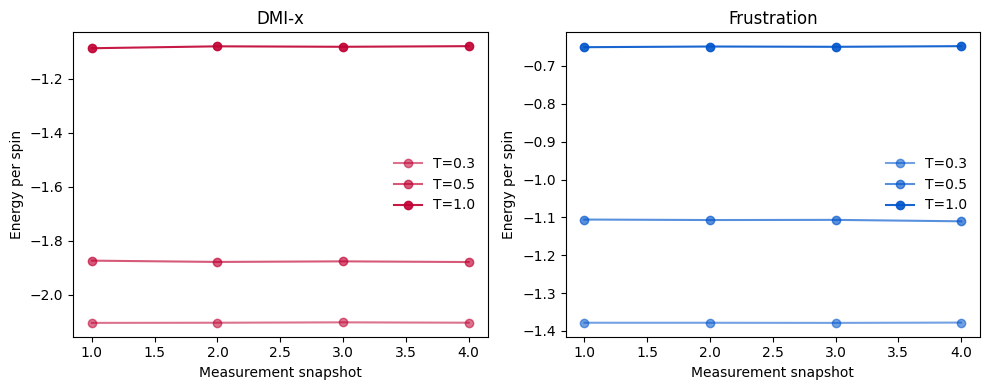

Snapshots saved in: /home/senji77/akhyar/research/notebooks/ANSW/mc_temperature_snapshots


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)

for ax, model, color in [
    (axes[0], 'dmi', '#C00032'),
    (axes[1], 'frustration', '#0055CC')
]:
    for t in T_TARGETS:
        tag = target_tag(t)
        with np.load(OUTPUT / f'mc_checks_{model}_T{tag}.npz') as check:
            energies = check['energy_per_spin']
        ax.plot(
            np.arange(1, len(energies) + 1),
            energies.mean(axis=1), 'o-', color=color,
            alpha=0.4 + 0.5 * t / max(T_TARGETS), label=f'T={t:.1f}'
        )
    ax.set_title('DMI-x' if model == 'dmi' else 'Frustration')
    ax.set_xlabel('Measurement snapshot')
    ax.set_ylabel('Energy per spin')
    ax.legend(frameon=False)

fig.tight_layout()
fig.savefig(OUTPUT / 'mc_snapshot_energy_checks.png', dpi=300, bbox_inches='tight')
plt.show()
print('Snapshots saved in:', OUTPUT)

In [10]:

from collections import Counter

def winding_test(t, seed):
    rng = np.random.default_rng(seed)

    winding_initial = np.array(
        [7] * (REPLICAS // 2) + [8] * (REPLICAS - REPLICAS // 2)
    )

    x = np.arange(L)[None, :, None]

    phase = (
        2 * np.pi * winding_initial[:, None, None] * x / L
        + rng.uniform(0, 2 * np.pi, (REPLICAS, 1, 1))
    )

    spins = np.zeros((REPLICAS, L, L, 3), dtype=np.float32)
    spins[..., 1] = np.cos(phase)
    spins[..., 2] = np.sin(phase)

    spins += 0.02 * rng.normal(size=spins.shape).astype(np.float32)
    spins /= np.linalg.norm(spins, axis=-1, keepdims=True)

    d_spins = cuda.to_device(spins)
    d_counts = cuda.device_array((REPLICAS, N_PER_COLOR), dtype=np.int32)
    d_sigma = cuda.to_device(np.array([0.6], dtype=np.float32))

    rng_states = create_xoroshiro128p_states(
        REPLICAS * N_PER_COLOR, seed=seed
    )

    for _ in range(200000 // ADAPT_EVERY):
        gpu_sweeps[REPLICAS, N_PER_COLOR](
            d_spins, d_counts, rng_states,
            np.float32(t), d_sigma, np.float32(B_z),
            1, np.float32(J), np.float32(J2),
            np.float32(D), ADAPT_EVERY
        )

        adapt_sigma_gpu[1, 256](
            d_counts, d_sigma, N, ADAPT_EVERY
        )

    history = []

    for step in range(5000, 100001, 5000):
        gpu_sweeps[REPLICAS, N_PER_COLOR](
            d_spins, d_counts, rng_states,
            np.float32(t), d_sigma, np.float32(B_z),
            1, np.float32(J), np.float32(J2),
            np.float32(D), 5000
        )

        if step % 20000 == 0:
            current = d_spins.copy_to_host()
            F = np.fft.rfft(current.mean(axis=2), axis=1)
            intensity = np.sum(np.abs(F) ** 2, axis=-1)

            winding_final = (
                np.argmax(intensity[:, 4:12], axis=1) + 4
            )

            energy = (
                -J * np.sum(
                    current * np.roll(current, -1, axis=1),
                    axis=(1, 2, 3)
                )
                -J * np.sum(
                    current * np.roll(current, -1, axis=2),
                    axis=(1, 2, 3)
                )
                +J2 * np.sum(
                    current * np.roll(current, -2, axis=1),
                    axis=(1, 2, 3)
                )
            ) / N

            history.append((step, winding_final.copy(), energy.copy()))

            print(f"\nT={t:.1f} | Measurement sweeps={step}")

            for initial in [7, 8]:
                mask = winding_initial == initial
                counts = dict(sorted(Counter(winding_final[mask]).items()))

                print(
                    f"Initial n={initial} | "
                    f"Final distribution={counts} | "
                    f"E/N={energy[mask].mean():.6f}"
                )

    return history


history_T01 = winding_test(0.1, 7301)
history_T03 = winding_test(0.3, 8301)



T=0.1 | Measurement sweeps=20000
Initial n=7 | Final distribution={np.int64(7): 12, np.int64(8): 4} | E/N=-1.603377
Initial n=8 | Final distribution={np.int64(8): 16} | E/N=-1.605229

T=0.1 | Measurement sweeps=40000
Initial n=7 | Final distribution={np.int64(7): 13, np.int64(8): 3} | E/N=-1.603294
Initial n=8 | Final distribution={np.int64(8): 16} | E/N=-1.605071

T=0.1 | Measurement sweeps=60000
Initial n=7 | Final distribution={np.int64(7): 10, np.int64(8): 6} | E/N=-1.603644
Initial n=8 | Final distribution={np.int64(8): 16} | E/N=-1.605276

T=0.1 | Measurement sweeps=80000
Initial n=7 | Final distribution={np.int64(7): 12, np.int64(8): 4} | E/N=-1.603649
Initial n=8 | Final distribution={np.int64(8): 16} | E/N=-1.605361

T=0.1 | Measurement sweeps=100000
Initial n=7 | Final distribution={np.int64(7): 11, np.int64(8): 5} | E/N=-1.603858
Initial n=8 | Final distribution={np.int64(8): 16} | E/N=-1.605527

T=0.3 | Measurement sweeps=20000
Initial n=7 | Final distribution={np.int64(7)

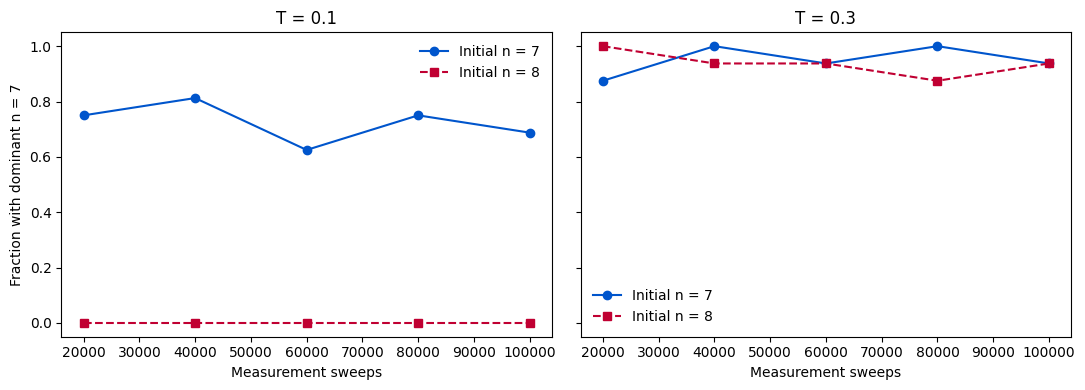

In [11]:

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, history, t in zip(
    axes,
    [history_T01, history_T03],
    [0.1, 0.3]
):
    steps = np.array([h[0] for h in history])

    fraction_7 = np.array([
        np.mean(h[1][:16] == 7) for h in history
    ])

    fraction_8 = np.array([
        np.mean(h[1][16:] == 7) for h in history
    ])

    ax.plot(
        steps, fraction_7,
        "o-", color="#0055CC",
        label="Initial n = 7"
    )

    ax.plot(
        steps, fraction_8,
        "s--", color="#C00032",
        label="Initial n = 8"
    )

    ax.set_title(f"T = {t}")
    ax.set_xlabel("Measurement sweeps")
    ax.set_ylim(-0.05, 1.05)
    ax.legend(frameon=False)

axes[0].set_ylabel("Fraction with dominant n = 7")

plt.tight_layout()
plt.savefig("winding_population_vs_sweeps.png", dpi=400, bbox_inches="tight")
plt.savefig("winding_population_vs_sweeps.pdf", bbox_inches="tight")
plt.show()
